# Demo: Text Representation & Embedding Techniques in NLP

Notebook minh hoạ các kỹ thuật biểu diễn văn bản trong bài survey **"A Survey of Text Representation and Embedding Techniques in NLP"** (Patil, Boit, Gudivada, Nandigam – *IEEE Access*, 2023).

Mỗi mục đi theo đúng trình tự của bài báo và dùng lại các ví dụ gốc (câu *"he started driving when he was 22 years old"*, ví dụ `house` trong TF, bảng TF-IDF, bảng HAL...) để đối chiếu kết quả.

| # | Nhóm | Kỹ thuật |
|---|------|----------|
| 1 | Rule-based | Regular expression, fuzzy matching |
| 2 | Statistical – Discrete | One-Hot, Bag of Words, Category-based, N-gram, TF/NTF, TF-IDF, HAL |
| 3 | Dimensionality reduction | DF, TFV, Mean TF-IDF, Information Gain · LSI, LDA, ICA, Random Indexing |
| 4 | Conceptual / Density | Explicit Semantic Analysis (ESA), Gaussian embedding |
| 5 | Neural – Static | Word2Vec (skip-gram tự cài bằng NumPy), PPMI+SVD (GloVe-like), FastText (subword) |
| 6 | Neural – Dynamic | Contextual embedding (mô phỏng attention), cách dùng BERT thật |

> **Lưu ý:** môi trường chạy demo không có `gensim`/`torch`/`nltk`, nên notebook chỉ dùng `numpy`, `pandas`, `scikit-learn`, `matplotlib`. Các mô hình neural được cài lại ở dạng thu nhỏ (toy) trên corpus nhỏ để thấy được cơ chế, không nhằm đạt độ chính xác như mô hình thật.

In [1]:
import re, math, difflib, itertools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation, FastICA

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

## 1. Regular Expressions – hướng rule-based (Section II)

Giai đoạn đầu của NLP dựa vào **khớp mẫu chính xác** (regex / CFG) rồi đến **khớp gần đúng (fuzzy)**. Hệ thống chỉ quan tâm thứ tự và sự trùng khớp của chuỗi, **không** quan tâm nghĩa.

In [2]:
docs = ["I love ice cream", "She hates cold weather", "He loves icecream a lot"]

# 1) Khớp chính xác bằng regex
pattern = re.compile(r"\bice cream\b", re.I)
print("== Exact matching ==")
for d in docs:
    print(bool(pattern.search(d)), "|", d)

# 2) Khớp gần đúng: chấp nhận sai khác nhỏ (ngưỡng)
def fuzzy_score(query, text):
    words, n = text.lower().split(), len(query.split())
    return max(difflib.SequenceMatcher(None, query, " ".join(words[i:i+n])).ratio()
               for i in range(len(words) - n + 1))

print("\n== Fuzzy matching (ngưỡng 0.8) ==")
for d in docs:
    s = fuzzy_score("ice cream", d)
    print(f"{s:.2f}", s >= 0.8, "|", d)

# 3) Chatbot theo luật if-then (scripted response)
rules = [(r"\b(hi|hello)\b", "Chào bạn!"),
         (r"\bprice of (\w+)", "Mình sẽ tra giá của {0}."),
         (r"\b(bye|goodbye)\b", "Hẹn gặp lại!")]
def bot(msg):
    for pat, reply in rules:
        m = re.search(pat, msg, re.I)
        if m:
            return reply.format(*m.groups())
    return "Xin lỗi, mình chưa hiểu."
for q in ["hello there", "what is the price of laptops", "tell me a joke"]:
    print(q, "->", bot(q))

== Exact matching ==
True | I love ice cream
False | She hates cold weather
False | He loves icecream a lot

== Fuzzy matching (ngưỡng 0.8) ==
1.00 True | I love ice cream
0.38 False | She hates cold weather
0.84 True | He loves icecream a lot
hello there -> Chào bạn!
what is the price of laptops -> Mình sẽ tra giá của laptops.
tell me a joke -> Xin lỗi, mình chưa hiểu.


## 2. Discrete Vector Space (Section III)

### 2.1 One-Hot Encoding (OHE)
Mỗi từ → vector chỉ có một phần tử bằng 1. Ma trận có kích thước `(số từ trong câu) × |V|`. Bài báo dùng câu *"he started driving when he was 22 years old"* → ma trận **(9, 8)**.

In [3]:
sentence = "he started driving when he was 22 years old"
tokens = sentence.split()
vocab = sorted(set(tokens))
idx = {w: i for i, w in enumerate(vocab)}

ohe = np.zeros((len(tokens), len(vocab)), dtype=int)
for r, w in enumerate(tokens):
    ohe[r, idx[w]] = 1

print("Shape:", ohe.shape, "(khớp Table 1 của bài báo: (9, 8))")
display(pd.DataFrame(ohe, index=tokens, columns=vocab))

# Giữ nguyên thứ tự từ -> khôi phục lại câu gốc
rebuilt = " ".join(vocab[row.argmax()] for row in ohe)
print("Khôi phục câu:", rebuilt)

# Hạn chế: không có thông tin ngữ nghĩa
cold, freezing, hot = (np.eye(3)[i] for i in range(3))
print("\ndot(cold, freezing) =", cold @ freezing, "| dot(freezing, hot) =", freezing @ hot)
print("dist(cold, freezing) =", round(np.linalg.norm(cold - freezing), 3),
      "| dist(freezing, hot) =", round(np.linalg.norm(freezing - hot), 3))

Shape: (9, 8) (khớp Table 1 của bài báo: (9, 8))


,22,driving,he,old,started,was,when,years
he,0,0,1,0,0,0,0,0
started,0,0,0,0,1,0,0,0
driving,0,1,0,0,0,0,0,0
when,0,0,0,0,0,0,1,0
he,0,0,1,0,0,0,0,0
was,0,0,0,0,0,1,0,0
22,1,0,0,0,0,0,0,0
years,0,0,0,0,0,0,0,1
old,0,0,0,1,0,0,0,0


Khôi phục câu: he started driving when he was 22 years old

dot(cold, freezing) = 0.0 | dot(freezing, hot) = 0.0
dist(cold, freezing) = 1.414 | dist(freezing, hot) = 1.414


Dot product giữa hai one-hot khác nhau luôn bằng 0 và mọi cặp từ cách nhau như nhau ⇒ **không phản ánh quan hệ nghĩa** (bài báo nhấn mạnh OHE bỏ qua ngữ cảnh; cách giải thích khoảng cách theo thứ tự bảng chữ cái trong bài chỉ mang tính minh hoạ, kết luận chung vẫn là: OHE không đo được độ tương tự ngữ nghĩa). Ngoài ra ma trận rất **thưa** và tốn chiều.

### 2.2 Bag of Words (BoW)
Mỗi dòng là một câu/tài liệu, mỗi cột là một từ; giá trị là tần suất (non-binary) hoặc có/không (binary).

In [4]:
corpus = ["Sam started driving when he was 22 years old.",
          "He was passionate about swimming, and won several competitions.",
          "He didn't like watching television, as he preferred outdoor activities."]

cv = CountVectorizer(token_pattern=r"[\w']+", lowercase=True)
bow = cv.fit_transform(corpus)
print("Shape (số câu, |V|):", bow.shape, "(bài báo ghi (3, 25); lệch 1 cột do cách tách từ)")
bow_df = pd.DataFrame(bow.toarray(), index=["Sent1", "Sent2", "Sent3"], columns=cv.get_feature_names_out())
display(bow_df.loc[:, (bow_df != 0).any()].T)

bin_bow = CountVectorizer(token_pattern=r"[\w']+", binary=True).fit_transform(corpus)
sparsity = 1 - bow.nnz / np.prod(bow.shape)
print(f"Độ thưa (sparsity) của BoW: {sparsity:.0%}")

# Độ tương tự bằng dot product (công thức (1) trong bài)
print("\nDot product giữa các câu:\n", (bow @ bow.T).toarray())

Shape (số câu, |V|): (3, 24) (bài báo ghi (3, 25); lệch 1 cột do cách tách từ)


,Sent1,Sent2,Sent3
22,1,0,0
about,0,1,0
activities,0,0,1
and,0,1,0
as,0,0,1
competitions,0,1,0
didn't,0,0,1
driving,1,0,0
he,1,1,2
like,0,0,1


Độ thưa (sparsity) của BoW: 62%

Dot product giữa các câu:
 [[ 9  2  2]
 [ 2  9  2]
 [ 2  2 12]]


In [5]:
# Hạn chế 1: BoW chỉ khớp từ chính xác -> đồng nghĩa không được nhận ra
a, b, c = "the movie was great", "the film was excellent", "the movie was awful"
M = CountVectorizer().fit_transform([a, b, c]).toarray()
print("sim(great, excellent) :", M[0] @ M[1], "  <- cùng nghĩa nhưng chỉ chung 'the', 'was'")
print("sim(great, awful)     :", M[0] @ M[2], "  <- trái nghĩa nhưng chung nhiều từ hơn!")

# Hạn chế 2: mất thứ tự từ
x, y = "dog bites man", "man bites dog"
Mx = CountVectorizer().fit_transform([x, y]).toarray()
print("\nBoW 'dog bites man' == 'man bites dog' ?", bool((Mx[0] == Mx[1]).all()))

sim(great, excellent) : 2   <- cùng nghĩa nhưng chỉ chung 'the', 'was'
sim(great, awful)     : 3   <- trái nghĩa nhưng chung nhiều từ hơn!

BoW 'dog bites man' == 'man bites dog' ? True


### 2.3 Category-Based Embedding (CBE)
Số cột = số **danh mục định sẵn** (ví dụ positive / negative) → ma trận nhỏ, dày. Bài báo dùng 4 câu cảm xúc, kết quả khớp **Table 3**. Từ điển (lexicon) ở đây được viết tay (kiểu *heuristic*) thay cho VADER/AFINN.

In [6]:
reviews = ["I am feeling fresh and happy because I had gone on vacation.",
           "I did not enjoy reading his novel.",
           "I hated the movie as the plot was missing.",
           "The meal at this restaurant is delicious."]

lexicon = {"fresh": "pos", "happy": "pos", "enjoy": "pos", "delicious": "pos",
           "hated": "neg", "missing": "neg", "not": "neg"}

def cbe(text, lex):
    cnt = collections.Counter(lex[w] for w in re.findall(r"[a-z']+", text.lower()) if w in lex)
    p, n = cnt["pos"], cnt["neg"]
    overall = "Positive" if p > n else "Negative" if n > p else "Neutral"
    return p, n, overall

table3 = pd.DataFrame([cbe(r, lexicon) for r in reviews],
                      columns=["Positive", "Negative", "Overall"],
                      index=[f"Sentence-{i}" for i in range(1, 5)])
print("Khớp Table 3 của bài báo:")
display(table3)

# Sentence-2 bị xếp 'Neutral' vì 'not' và 'enjoy' được đếm riêng -> dùng n-gram sửa lỗi
lexicon_ng = dict(lexicon); lexicon_ng.pop("not")
def cbe_bigram(text, lex, bigram_lex):
    t = text.lower()
    p = n = 0
    for bg, pol in bigram_lex.items():
        if bg in t:
            t = t.replace(bg, " ")
            p += pol == "pos"; n += pol == "neg"
    cnt = collections.Counter(lex[w] for w in re.findall(r"[a-z']+", t) if w in lex)
    p, n = p + cnt["pos"], n + cnt["neg"]
    return p, n, ("Positive" if p > n else "Negative" if n > p else "Neutral")

bigram_lex = {"not enjoy": "neg", "not like": "neg"}
print("Sau khi thêm bi-gram 'not enjoy':", cbe_bigram(reviews[1], lexicon_ng, bigram_lex))

Khớp Table 3 của bài báo:


,Positive,Negative,Overall
Sentence-1,2,0,Positive
Sentence-2,1,1,Neutral
Sentence-3,0,2,Negative
Sentence-4,1,0,Positive


Sau khi thêm bi-gram 'not enjoy': (0, 1, 'Negative')


### 2.4 N-grams
Dùng cửa sổ `n` từ để **giữ một phần thứ tự** (ví dụ `not playing`, `ice cream`). Nhược điểm: số tổ hợp tăng theo hàm mũ với `n`.

In [7]:
corpus_ng = ["She can't stand her.", "She was fed up of the assignments.", "He screwed up the exam.",
             "He did not like trekking.", "He could not bear the pain of separation."]

ng = CountVectorizer(ngram_range=(2, 3), token_pattern=r"[\w']+")
ng.fit(corpus_ng)
terms = ng.get_feature_names_out()
interesting = [t for t in terms if t in {"can't stand", "fed up", "screwed up", "did not like", "could not bear", "not like", "not bear"}]
print("Số n-gram (2..3) tạo ra:", len(terms))
print("N-gram mang nghĩa nhóm từ:", interesting)

# Bùng nổ tổ hợp: 5-gram trên từ điển 100.000 từ
print("\nSố tổ hợp 5-gram với |V|=100000:", f"{100000**5 - 1:.3e}")

Số n-gram (2..3) tạo ra: 43
N-gram mang nghĩa nhóm từ: ["can't stand", 'could not bear', 'did not like', 'fed up', 'not bear', 'not like', 'screwed up']

Số tổ hợp 5-gram với |V|=100000: 1.000e+25


### 2.5 Term Frequency (TF) và Normalized TF (NTF)
Ví dụ gốc (Table 4): từ *house* xuất hiện 50 lần trong Doc-A (150 từ) và 1000 lần trong Doc-B (1.000.000 từ). Chỉ nhìn TF thì B "liên quan" hơn, nhưng sau khi chuẩn hoá thì A mới đúng.

In [8]:
tf = {"Doc-A": (50, 150), "Doc-B": (1000, 1_000_000)}
rows = [(d, c, n, c / n) for d, (c, n) in tf.items()]
display(pd.DataFrame(rows, columns=["Doc", "'house' TF", "Doc length", "Normalized TF"]))

,Doc,'house' TF,Doc length,Normalized TF
0,Doc-A,50,150,0.333333
1,Doc-B,1000,1000000,0.001000


### 2.6 TF-IDF
$$w_{i,j} = tf_{i,j} \cdot \log\frac{N}{df_i}$$

Bài báo dùng 4 tài liệu A–D (Table 5): A, C nói về **chi phí sửa chữa nhà**, B, D nói về **tiện ích khu dân cư**. Bảng IDF trong bài viết dưới dạng tỉ số `N/df`; công thức (3) dùng `log`. Dưới đây tính cả hai.

In [9]:
terms = ["house", "apartment", "repair", "maintenance", "labor cost", "safety", "commute", "school", "grocery", "env"]
counts = np.array([[125, 210, 100, 200, 32,  0,  0,  0,  0,  0],   # doc A
                   [150, 235,   0,   0,  0, 71, 55, 81, 32, 64],   # doc B
                   [175, 261, 150, 350, 21,  0,  0,  0,  0,  0],   # doc C
                   [140, 284,   0,   0,  0, 98, 44, 76, 28, 53]])  # doc D
names = list("ABCD")
N = counts.shape[0]
df_ = (counts > 0).sum(axis=0)

print("df   :", dict(zip(terms, df_.tolist())))
print("N/df :", dict(zip(terms, (N / df_).round(2).tolist())), " <- khớp hàng IDF của Table 5")

ntf = counts / counts.sum(axis=1, keepdims=True)         # normalized TF
idf_log = np.log(N / df_)
tfidf = ntf * idf_log

def sim_table(M, title):
    s = pd.DataFrame(cosine_similarity(M), index=names, columns=names).round(2)
    print(f"\n{title}"); display(s)

sim_table(ntf, "Cosine similarity dùng NTF (house/apartment lấn át)")
sim_table(tfidf, "Cosine similarity dùng TF-IDF (A~C và B~D tách bạch)")

df   : {'house': 4, 'apartment': 4, 'repair': 2, 'maintenance': 2, 'labor cost': 2, 'safety': 2, 'commute': 2, 'school': 2, 'grocery': 2, 'env': 2}
N/df : {'house': 1.0, 'apartment': 1.0, 'repair': 2.0, 'maintenance': 2.0, 'labor cost': 2.0, 'safety': 2.0, 'commute': 2.0, 'school': 2.0, 'grocery': 2.0, 'env': 2.0}  <- khớp hàng IDF của Table 5

Cosine similarity dùng NTF (house/apartment lấn át)


,A,B,C,D
A,1.00,0.66,0.99,0.67
B,0.66,1.00,0.57,0.99
C,0.99,0.57,1.00,0.57
D,0.67,0.99,0.57,1.00



Cosine similarity dùng TF-IDF (A~C và B~D tách bạch)


,A,B,C,D
A,1.00,0.00,0.99,0.00
B,0.00,1.00,0.00,0.98
C,0.99,0.00,1.00,0.00
D,0.00,0.98,0.00,1.00


In [10]:
# TF-IDF "thực tế" bằng scikit-learn + tìm kiếm tài liệu theo truy vấn
docs = ["repair and maintenance of the house costs labor",
        "the apartment is close to school and grocery stores",
        "house repair needs skilled labor and maintenance budget",
        "safe neighborhood with good schools and short commute"]
tv = TfidfVectorizer(stop_words="english")
X = tv.fit_transform(docs)
query = tv.transform(["house repair cost"])
scores = cosine_similarity(query, X).ravel()
for rank in np.argsort(-scores):
    print(f"{scores[rank]:.3f} | {docs[rank]}")

0.597 | repair and maintenance of the house costs labor
0.476 | house repair needs skilled labor and maintenance budget
0.000 | the apartment is close to school and grocery stores
0.000 | safe neighborhood with good schools and short commute


### 2.7 Hyperspace Analogue to Language (HAL)
Xây **ma trận đồng xuất hiện** (co-occurrence) với cửa sổ trượt; từ càng gần thì trọng số càng lớn (`trọng số = window − khoảng cách`). Với câu *"He ran towards the grocery store"*, window = 4, kết quả khớp **Table 6**.

,He,ran,towards,the,grocery,store
He,0,0,0,0,0,0
ran,3,0,0,0,0,0
towards,2,3,0,0,0,0
the,1,2,3,0,0,0
grocery,0,1,2,3,0,0
store,0,0,1,2,3,0


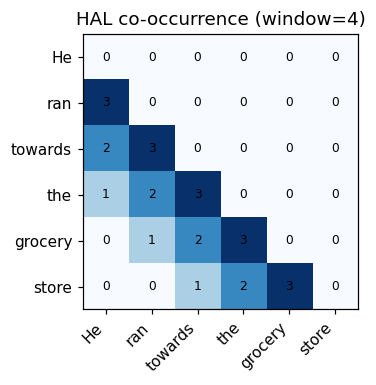

In [11]:
def hal_matrix(tokens, window=4):
    vocab = list(dict.fromkeys(tokens))
    ix = {w: i for i, w in enumerate(vocab)}
    M = np.zeros((len(vocab), len(vocab)), dtype=int)
    for i, w in enumerate(tokens):
        for d in range(1, window):                 # khoảng cách 1..window-1
            if i - d >= 0:
                M[ix[w], ix[tokens[i - d]]] += window - d
    return pd.DataFrame(M, index=vocab, columns=vocab)

hal = hal_matrix("He ran towards the grocery store".split(), window=4)
display(hal)

# Trực quan hoá
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(hal.values, cmap="Blues")
ax.set_xticks(range(len(hal))); ax.set_xticklabels(hal.columns, rotation=45, ha="right")
ax.set_yticks(range(len(hal))); ax.set_yticklabels(hal.index)
for i in range(len(hal)):
    for j in range(len(hal)):
        ax.text(j, i, hal.values[i, j], ha="center", va="center", fontsize=8)
ax.set_title("HAL co-occurrence (window=4)")
plt.tight_layout(); plt.show()

## 3. Dimensionality Reduction (Section IV)

Ma trận TF-IDF/BoW rất lớn và thưa ("lời nguyền số chiều"). Có hai hướng: **chọn đặc trưng** (giữ top-k) và **biến đổi đặc trưng** (chiếu sang không gian mới).

### 3.1 Feature Selection: DF, TFV, Mean TF-IDF, Information Gain

In [12]:
texts = ["the team won the football match", "the player scored a goal in the match",
         "the coach praised the team after the game", "a great goal decided the football game",
         "the new software update fixes the server bug", "the developer wrote code for the cloud server",
         "the software model uses data and algorithm", "the network server crashed after the update"]
labels = np.array(["sport"] * 4 + ["tech"] * 4)

cvf = CountVectorizer(stop_words="english")
C = cvf.fit_transform(texts).toarray()
terms_f = cvf.get_feature_names_out()
N = C.shape[0]

# 1) Document Frequency
DF = (C > 0).sum(axis=0)

# 2) Term-Frequency Variance: sum(tf^2) - (1/N) (sum tf)^2   (công thức 5)
TFV = (C ** 2).sum(axis=0) - (C.sum(axis=0) ** 2) / N

# 3) Mean TF-IDF (công thức 6)
tfidf_f = TfidfVectorizer(stop_words="english").fit_transform(texts).toarray()
TI = tfidf_f.mean(axis=0)

# 4) Information Gain (công thức 7)
def entropy(y):
    if len(y) == 0: return 0.0
    p = np.array([(y == c).mean() for c in np.unique(y)])
    return float(-(p * np.log2(p)).sum())

def information_gain(Cbin, y):
    base, out = entropy(y), []
    for j in range(Cbin.shape[1]):
        t = Cbin[:, j] == 1
        out.append(base - t.mean() * entropy(y[t]) - (1 - t.mean()) * entropy(y[~t]))
    return np.array(out)
IG = information_gain((C > 0).astype(int), labels)

fs = pd.DataFrame({"DF": DF, "TFV": TFV.round(2), "MeanTFIDF": TI.round(3), "IG": IG.round(3)}, index=terms_f)
print("Top-8 theo từng tiêu chí:")
for col in fs.columns:
    print(f"  {col:10s}:", list(fs[col].sort_values(ascending=False).index[:8]))
display(fs.sort_values("IG", ascending=False).head(10))

Top-8 theo từng tiêu chí:
  DF        : ['server', 'game', 'goal', 'football', 'match', 'software', 'team', 'update']
  TFV       : ['server', 'game', 'goal', 'football', 'match', 'software', 'team', 'update']
  MeanTFIDF : ['server', 'match', 'team', 'football', 'goal', 'game', 'update', 'software']
  IG        : ['server', 'game', 'goal', 'football', 'match', 'software', 'team', 'update']


,DF,TFV,MeanTFIDF,IG
server,3,1.88,0.134,0.549
game,2,1.50,0.108,0.311
goal,2,1.50,0.108,0.311
football,2,1.50,0.111,0.311
match,2,1.50,0.116,0.311
software,2,1.50,0.096,0.311
team,2,1.50,0.116,0.311
update,2,1.50,0.106,0.311
coach,1,0.88,0.068,0.138
cloud,1,0.88,0.059,0.138


### 3.2 Feature Transformation

#### a) Latent Semantic Indexing (LSI)
LSI dùng **SVD** trên ma trận TF-IDF để tìm các "chủ đề" – tổ hợp tuyến tính của từ. Từ đồng nghĩa/cùng ngữ cảnh được gom vào cùng chiều. Ví dụ chủ đề *community* trong bài (education / shopping / transportation).

Topic 0:  [('bus', 0.37), ('commute', 0.31), ('ticket', 0.29), ('transportation', 0.27), ('school', 0.26), ('students', 0.25)]
Topic 1:  [('shopping', 0.35), ('buy', 0.31), ('mall', 0.3), ('market', 0.24), ('grocery', 0.24), ('store', 0.17)]
Topic 2:  [('ticket', 0.28), ('bus', 0.25), ('transportation', 0.25), ('airport', 0.21), ('commute', 0.18), ('shuttle', 0.14)]


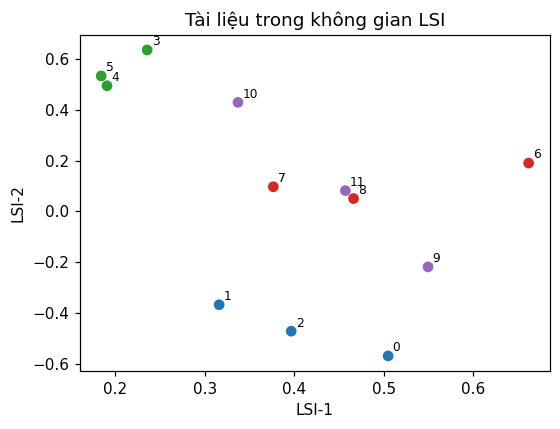

In [13]:
community = [
 "school students teacher classroom education university",
 "university bootcamp education degree students learning",
 "teacher school lesson education classroom homework",
 "grocery store shopping mall market buy",
 "mall shopping stores fashion buy discount",
 "supermarket grocery shopping market fresh food buy",
 "bus train transportation commute station ticket",
 "airport flight transportation airline ticket travel",
 "car bus traffic road commute transportation",
 "students commute by bus to school",
 "shopping mall near the train station",
 "airport shuttle bus ticket"]

tv = TfidfVectorizer()
Xc = tv.fit_transform(community)
svd = TruncatedSVD(n_components=3, random_state=0)
Z = svd.fit_transform(Xc)
fn = tv.get_feature_names_out()

for k, comp in enumerate(svd.components_):
    top = comp.argsort()[::-1][:6]
    print(f"Topic {k}: ", [(str(fn[i]), round(float(comp[i]), 2)) for i in top])

fig, ax = plt.subplots(figsize=(5.2, 4))
cols = ["tab:blue"] * 3 + ["tab:green"] * 3 + ["tab:red"] * 3 + ["tab:purple"] * 3
ax.scatter(Z[:, 0], Z[:, 1], c=cols)
for i, (x, y) in enumerate(Z[:, :2]):
    ax.annotate(str(i), (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("LSI-1"); ax.set_ylabel("LSI-2"); ax.set_title("Tài liệu trong không gian LSI")
plt.tight_layout(); plt.show()

#### b) Probabilistic LSI (PLSI) và Latent Dirichlet Allocation (LDA)
PLSI mô hình hoá $P(w|d)=\sum_k P(w|z_k)P(z_k|d)$ nhưng số tham số tăng tuyến tính theo số tài liệu ($kV+kM$) và không suy luận được cho tài liệu mới. **LDA** coi phân bố chủ đề là biến ẩn Dirichlet nên chỉ có $k+kV$ tham số và tổng quát hoá cho tài liệu chưa thấy. `scikit-learn` có LDA nên ta chạy trực tiếp.

In [14]:
cvl = CountVectorizer()
Cl = cvl.fit_transform(community)
lda = LatentDirichletAllocation(n_components=3, random_state=1, max_iter=200, doc_topic_prior=0.5,
                                topic_word_prior=0.05, learning_method="batch")
theta = lda.fit_transform(Cl)                    # P(z|d)
fnl = cvl.get_feature_names_out()

for k, comp in enumerate(lda.components_):
    top = comp.argsort()[::-1][:6]
    print(f"Topic {k}:", [fnl[i] for i in top])

print("\nPhân bố chủ đề của vài tài liệu (mỗi dòng cộng = 1):")
display(pd.DataFrame(theta[[0, 3, 6, 9, 10]], columns=[f"z{k}" for k in range(3)],
                     index=[community[i][:40] for i in [0, 3, 6, 9, 10]]).round(2))

# Tài liệu MỚI (chưa thấy khi huấn luyện) - đặc điểm mà PLSI không làm được
new_doc = cvl.transform(["students take the bus to school every morning"])
print("Chủ đề của tài liệu mới:", lda.transform(new_doc).round(2))
print("Số tham số LDA = k + kV =", 3 + 3 * Cl.shape[1])

Topic 0: ['bus', 'transportation', 'ticket', 'commute', 'airport', 'station']
Topic 1: ['education', 'students', 'school', 'teacher', 'university', 'classroom']
Topic 2: ['shopping', 'buy', 'mall', 'market', 'grocery', 'food']

Phân bố chủ đề của vài tài liệu (mỗi dòng cộng = 1):


,z0,z1,z2
school students teacher classroom educat,0.07,0.87,0.07
grocery store shopping mall market buy,0.07,0.07,0.87
bus train transportation commute station,0.87,0.07,0.07
students commute by bus to school,0.33,0.33,0.33
shopping mall near the train station,0.60,0.07,0.33


Chủ đề của tài liệu mới: [[0.38 0.38 0.23]]
Số tham số LDA = k + kV = 126


#### c) Independent Component Analysis (ICA)
ICA tách các **thành phần độc lập thống kê** (không chỉ trực giao như PCA/LSI) từ các hỗn hợp tuyến tính $x = As$. Minh hoạ kinh điển: trộn hai tín hiệu rồi tách lại (blind source separation).

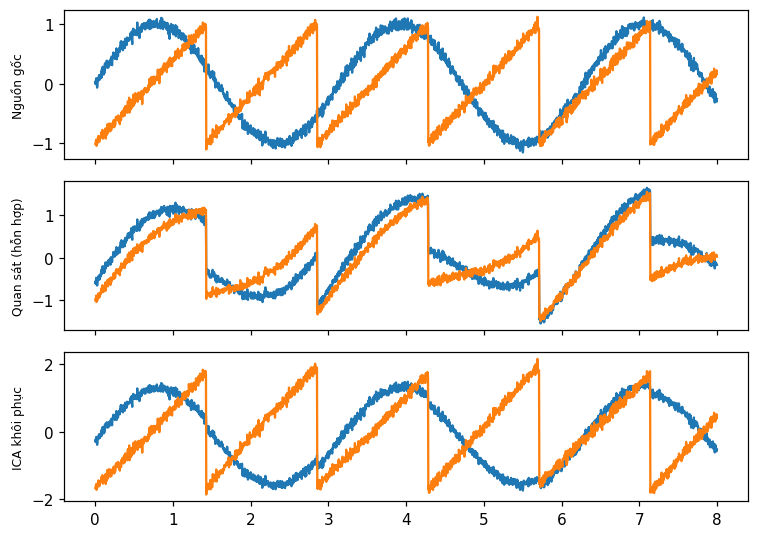

|corr| nguồn vs ICA:
 [[0.998 0.07 ]
 [0.083 0.997]]


In [15]:
from scipy import signal
rng = np.random.default_rng(0)
t = np.linspace(0, 8, 2000)
s1 = np.sin(2 * t)                               # nguồn 1: sin
s2 = signal.sawtooth(2 * np.pi * 0.7 * t)        # nguồn 2: răng cưa
S = np.c_[s1, s2] + 0.05 * rng.standard_normal((2000, 2))
A = np.array([[1.0, 0.6], [0.5, 1.0]])           # ma trận trộn (chưa biết trong thực tế)
X = S @ A.T

ica = FastICA(n_components=2, whiten="unit-variance", random_state=0)
S_hat = ica.fit_transform(X)

fig, axes = plt.subplots(3, 1, figsize=(7, 5), sharex=True)
for ax, data, title in zip(axes, [S, X, S_hat], ["Nguồn gốc", "Quan sát (hỗn hợp)", "ICA khôi phục"]):
    ax.plot(t, data); ax.set_ylabel(title, fontsize=8)
plt.tight_layout(); plt.show()

# Độ tương quan giữa nguồn và thành phần khôi phục (|r| ~ 1 nghĩa là tách tốt)
corr = np.abs(np.corrcoef(S.T, S_hat.T)[:2, 2:])
print("|corr| nguồn vs ICA:\n", corr.round(3))

#### d) Random Indexing (RI) – Johnson–Lindenstrauss
Chiếu ngẫu nhiên từ $d$ chiều xuống $k \ll d$ chiều mà vẫn **xấp xỉ giữ khoảng cách**: $X' = R X$. RI có tính **incremental** (không cần xem toàn bộ dữ liệu, không cần pha giảm chiều riêng) – khác với SVD.

5000 -> 400 chiều | tỉ lệ khoảng cách trung bình: 0.995 (độ lệch chuẩn 0.034)


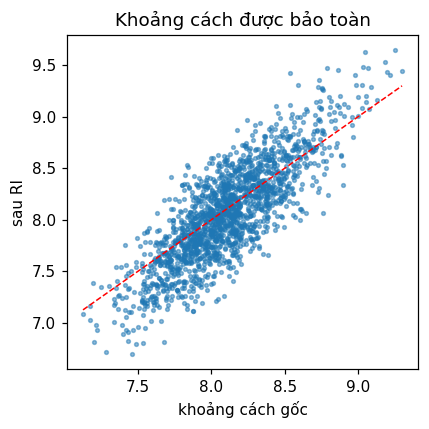

Tương quan cosine giữa BoW đầy đủ (41 chiều) và RI (300 chiều): 0.966


In [16]:
rng = np.random.default_rng(1)

# (1) Kiểm tra bổ đề J-L trên dữ liệu ngẫu nhiên nhiều chiều
d, k, n = 5000, 400, 60
X = rng.random((n, d)) * (rng.random((n, d)) < 0.02)       # thưa, 5000 chiều
R = rng.standard_normal((k, d)) / np.sqrt(k)               # ma trận ngẫu nhiên
Xp = X @ R.T
def pdist(M):
    G = M @ M.T; sq = np.diag(G)
    return np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * G, 0))[np.triu_indices(len(M), 1)]
d0, d1 = pdist(X), pdist(Xp)
print(f"{d} -> {k} chiều | tỉ lệ khoảng cách trung bình: {np.mean(d1 / d0):.3f} (độ lệch chuẩn {np.std(d1 / d0):.3f})")

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(d0, d1, s=6, alpha=.5); lim = [d0.min(), d0.max()]
ax.plot(lim, lim, "r--", lw=1); ax.set_xlabel("khoảng cách gốc"); ax.set_ylabel("sau RI")
ax.set_title("Khoảng cách được bảo toàn"); plt.tight_layout(); plt.show()

# (2) Random Indexing kiểu 'incremental': mỗi từ có index-vector thưa ±1, tài liệu = tổng index-vector
dim, nnz = 300, 6
index_vec = {}
def get_index_vec(w):
    if w not in index_vec:
        v = np.zeros(dim); pos = rng.choice(dim, nnz, replace=False)
        v[pos] = rng.choice([-1, 1], nnz); index_vec[w] = v
    return index_vec[w]

def ri_doc(text):                 # có thể cập nhật dần khi có dữ liệu mới
    return sum(get_index_vec(w) for w in text.split())

RI = np.array([ri_doc(t) for t in community])
full = CountVectorizer().fit_transform(community).toarray()
iu = np.triu_indices(len(community), 1)
r = np.corrcoef(cosine_similarity(full)[iu], cosine_similarity(RI)[iu])[0, 1]
print(f"Tương quan cosine giữa BoW đầy đủ ({full.shape[1]} chiều) và RI ({dim} chiều): {r:.3f}")

## 4. Conceptual Embedding – Explicit Semantic Analysis (Section V)

ESA biểu diễn văn bản bằng **vector trọng số trên các khái niệm** (bài gốc dùng các bài Wikipedia): $Text = W_1 \cdot Concept_1 + \dots + W_n \cdot Concept_n$. Dưới đây là phiên bản thu nhỏ với 5 "bài Wikipedia" tự viết.

In [17]:
concepts = {
 "Jaguar_(animal)": "jaguar big cat predator jungle rainforest hunting spotted fast animal",
 "Car":             "car engine wheels drive vehicle road speed fuel automobile",
 "Bank":            "bank money loan deposit account interest finance credit customer",
 "River":           "river water stream flow shore fish boat bridge mud",
 "Computer":        "computer software program data network code algorithm processor",
}
names_c = list(concepts)
tv_c = TfidfVectorizer()
Wc = tv_c.fit_transform(concepts.values())           # concept x word  (inverted index)

def esa(text):
    v = tv_c.transform([text])                       # từ -> khái niệm
    return (v @ Wc.T).toarray().ravel()              # interpretation vector

def show(text):
    iv = esa(text)
    top = np.argsort(-iv)[:3]
    print(f"{text!r:42s} ->", [(names_c[i], round(float(iv[i]), 2)) for i in top if iv[i] > 0])

for t in ["fast animal hunting in the jungle", "driving a vehicle at high speed",
          "deposit money at the bank", "fish in the river near the bridge"]:
    show(t)

print("\nĐộ liên quan ngữ nghĩa (cosine giữa interpretation vectors):")
pairs = [("a fast cat in the jungle", "speed of the car engine"),
         ("a fast cat in the jungle", "predator hunting animal"),
         ("loan and credit", "money in the account")]
for a, b in pairs:
    print(f"  {cosine_similarity([esa(a)], [esa(b)])[0, 0]:.2f}  | {a}  ~  {b}")

'fast animal hunting in the jungle'        -> [('Jaguar_(animal)', 0.63)]
'driving a vehicle at high speed'          -> [('Car', 0.47)]
'deposit money at the bank'                -> [('Bank', 0.58)]
'fish in the river near the bridge'        -> [('River', 0.58)]

Độ liên quan ngữ nghĩa (cosine giữa interpretation vectors):
  0.00  | a fast cat in the jungle  ~  speed of the car engine
  1.00  | a fast cat in the jungle  ~  predator hunting animal
  1.00  | loan and credit  ~  money in the account


## 5. Density Distribution Embedding – Gaussian embeddings (Section VI)

Mỗi từ là **một phân phối Gaussian** (mean + covariance) thay vì một điểm. Gaussian đơn mode bị "kéo" ở giữa khi từ đa nghĩa (*wing*), nên Athiwaratkun & Wilson đề xuất **hỗn hợp Gaussian** – mỗi thành phần là một nghĩa. Hình dưới là minh hoạ trực quan (không huấn luyện).

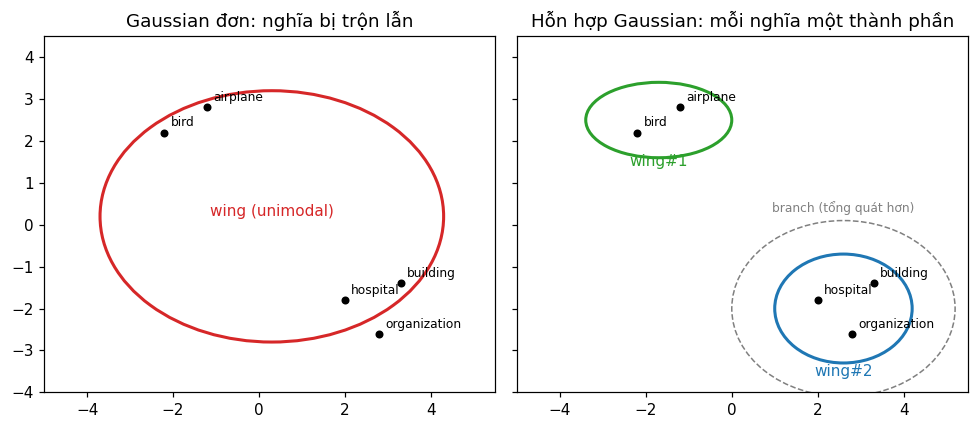

In [18]:
from matplotlib.patches import Ellipse
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)

pts = {"bird": (-2.2, 2.2), "airplane": (-1.2, 2.8), "hospital": (2.0, -1.8),
       "organization": (2.8, -2.6), "building": (3.3, -1.4)}
for ax in axes:
    for w, (x, y) in pts.items():
        ax.scatter(x, y, c="k", s=18); ax.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_xlim(-5, 5.5); ax.set_ylim(-4, 4.5)

# (trái) một Gaussian duy nhất cho 'wing' -> phương sai rất lớn, tâm lệch
axes[0].add_patch(Ellipse((0.3, 0.2), 8, 6, fill=False, ec="tab:red", lw=2))
axes[0].annotate("wing (unimodal)", (0.3, 0.2), ha="center", color="tab:red")
axes[0].set_title("Gaussian đơn: nghĩa bị trộn lẫn")

# (phải) hỗn hợp Gaussian cho 'wing' -> mỗi nghĩa một thành phần
axes[1].add_patch(Ellipse((-1.7, 2.5), 3.4, 1.8, fill=False, ec="tab:green", lw=2))
axes[1].add_patch(Ellipse((2.6, -2.0), 3.2, 2.6, fill=False, ec="tab:blue", lw=2))
axes[1].annotate("wing#1", (-1.7, 1.4), ha="center", color="tab:green")
axes[1].annotate("wing#2", (2.6, -3.6), ha="center", color="tab:blue")
axes[1].add_patch(Ellipse((2.6, -2.0), 5.2, 4.2, fill=False, ec="gray", ls="--"))
axes[1].annotate("branch (tổng quát hơn)", (2.6, 0.3), ha="center", color="gray", fontsize=8)
axes[1].set_title("Hỗn hợp Gaussian: mỗi nghĩa một thành phần")
plt.tight_layout(); plt.show()

## 6. Neural-network based embeddings (Section VII)

### 6.0 Corpus tổng hợp dùng chung
Để huấn luyện được trong vài giây, ta sinh một corpus nhỏ có cấu trúc: các chủ đề (tài chính, sông nước, động vật, công nghệ), từ đa nghĩa **bank**, và các cặp **vua/hoàng hậu, đàn ông/phụ nữ** (để thử phép tương tự). Mô hình thật (Word2Vec, GloVe) dùng hàng tỉ từ; ở đây chỉ để thấy cơ chế.

In [19]:
rng = np.random.default_rng(7)

topics = {
 "finance": ["bank", "money", "loan", "deposit", "account", "cash", "interest", "credit", "investor", "market"],
 "river":   ["bank", "river", "water", "shore", "fish", "boat", "mud", "stream", "fisherman", "bridge"],
 "animal":  ["dog", "cat", "horse", "bird", "wolf", "fox", "barks", "runs", "hunts", "forest"],
 "tech":    ["computer", "software", "network", "data", "server", "code", "model", "algorithm", "program", "cloud"],
}
royal_pool  = ["crown", "throne", "palace", "rules", "kingdom", "royal", "castle"]
common_pool = ["house", "street", "work", "walks", "market", "friend", "city"]
pairs = [("king", "queen", "royal"), ("prince", "princess", "royal"),
         ("man", "woman", "common"), ("boy", "girl", "common"),
         ("uncle", "aunt", "common"), ("actor", "actress", "common")]

sentences = []
for _ in range(1500):                                  # câu theo chủ đề
    pool = topics[rng.choice(list(topics))]
    sentences.append(list(rng.choice(pool, rng.integers(5, 8))))
for _ in range(1200):                                  # câu về giới tính / vương quyền
    m, f, kind = pairs[rng.integers(len(pairs))]
    pool = royal_pool if kind == "royal" else common_pool
    word, pron = (m, rng.choice(["he", "his", "him"])) if rng.random() < .5 else (f, rng.choice(["she", "her"]))
    sentences.append([word, pron] + list(rng.choice(pool, 4)))
for _ in range(200):                                   # biến thể hình thái cho FastText
    pool = royal_pool
    sentences.append([rng.choice(["kingdom", "kingdoms"]), rng.choice(["king", "queen"])] + list(rng.choice(pool, 3)))

vocab_all = sorted({w for s in sentences for w in s})
print("Số câu:", len(sentences), "| |V| =", len(vocab_all))
print("Ví dụ:", [str(w) for w in sentences[0]], [str(w) for w in sentences[-1]], sep="\n  ")

Số câu: 2900 | |V| = 70
Ví dụ:
  ['model', 'program', 'code', 'algorithm', 'program', 'network']
  ['kingdoms', 'queen', 'castle', 'kingdom', 'kingdom']


### 6.1 Word2Vec – Skip-gram với Negative Sampling (tự cài bằng NumPy)
Bài báo: *CBOW* dự đoán từ đích từ ngữ cảnh, *Skip-gram* dự đoán ngữ cảnh từ từ đích; cả hai **không có tầng ẩn phi tuyến** nên rất rẻ. Dưới đây cài skip-gram + negative sampling. Tham số `subword=True` biến nó thành **FastText** (vector từ = tổng vector các character n-gram).

In [20]:
def char_ngrams(word, nmin=3, nmax=5):
    w = f"<{word}>"
    return [w[i:i + n] for n in range(nmin, nmax + 1) for i in range(len(w) - n + 1)]

class SkipGram:
    def __init__(self, sentences, dim=32, window=3, neg=5, lr=0.05, subword=False, seed=0):
        self.rng = np.random.default_rng(seed)
        self.sentences, self.dim, self.window, self.neg, self.lr = sentences, dim, window, neg, lr
        self.vocab = sorted({w for s in sentences for w in s})
        self.w2i = {w: i for i, w in enumerate(self.vocab)}
        V = len(self.vocab)
        cnt = collections.Counter(w for s in sentences for w in s)
        p = np.array([cnt[w] for w in self.vocab], float) ** 0.75
        self.noise = p / p.sum()
        self.subword = subword
        if subword:
            grams = sorted({g for w in self.vocab for g in char_ngrams(w)})
            self.g2i = {g: V + i for i, g in enumerate(grams)}
            n_in = V + len(grams)
        else:
            n_in = V
        self.W_in = (self.rng.random((n_in, dim)) - .5) / dim
        self.W_out = np.zeros((V, dim))

    def rows(self, word):
        r = [self.w2i[word]] if word in self.w2i else []
        if self.subword:
            r += [self.g2i[g] for g in char_ngrams(word) if g in self.g2i]
        return np.array(r)

    def vec(self, word):
        r = self.rows(word)
        return self.W_in[r].mean(axis=0) if len(r) else None

    def fit(self, epochs=4):
        sig = lambda x: 1 / (1 + np.exp(-x))
        row_cache = {w: self.rows(w) for w in self.vocab}
        for ep in range(epochs):
            lr = self.lr * (1 - ep / epochs)
            for s in self.sentences:
                for i, c in enumerate(s):
                    rc = row_cache[c]
                    for j in range(max(0, i - self.window), min(len(s), i + self.window + 1)):
                        if j == i: continue
                        o = self.w2i[s[j]]
                        targets = np.r_[o, self.rng.choice(len(self.vocab), self.neg, p=self.noise)]
                        labels = np.r_[1, np.zeros(self.neg)]
                        h = self.W_in[rc].mean(axis=0)
                        out = self.W_out[targets]
                        g = sig(out @ h) - labels
                        grad_h = g @ out
                        np.add.at(self.W_out, targets, -lr * g[:, None] * h)
                        np.add.at(self.W_in, rc, -lr * grad_h / len(rc))
        return self

    def matrix(self):
        M = np.array([self.vec(w) for w in self.vocab])
        return M / np.linalg.norm(M, axis=1, keepdims=True)

    def most_similar(self, word, topn=5, positive=None, negative=None, exclude=()):
        M = self.matrix()
        if positive is None:
            q = M[self.w2i[word]]; ex = {word}
        else:
            q = sum(M[self.w2i[w]] for w in positive) - sum(M[self.w2i[w]] for w in (negative or []))
            ex = set(positive) | set(negative or [])
        q = q / np.linalg.norm(q)
        sims = M @ q
        return [(str(self.vocab[i]), round(float(sims[i]), 3)) for i in np.argsort(-sims) if self.vocab[i] not in ex | set(exclude)][:topn]

import time
t0 = time.time()
w2v = SkipGram(sentences, dim=32, window=3, neg=5, lr=0.05, subword=False, seed=0).fit(epochs=4)
print(f"Huấn luyện xong trong {time.time() - t0:.1f}s")

for w in ["bank", "dog", "server", "king"]:
    print(f"{w:8s} ->", w2v.most_similar(w, 5))

Huấn luyện xong trong 48.0s
bank     -> [('fish', 0.806), ('mud', 0.806), ('water', 0.789), ('stream', 0.789), ('boat', 0.789)]
dog      -> [('runs', 0.999), ('barks', 0.999), ('hunts', 0.999), ('forest', 0.998), ('fox', 0.996)]
server   -> [('computer', 0.999), ('cloud', 0.998), ('algorithm', 0.998), ('program', 0.996), ('data', 0.996)]
king     -> [('prince', 0.959), ('queen', 0.722), ('castle', 0.719), ('palace', 0.708), ('rules', 0.705)]


In [21]:
# Phép tương tự (analogy): king - man + woman ≈ queen ?
print("king - man + woman  ->", w2v.most_similar(None, 3, positive=["king", "woman"], negative=["man"]))
print("prince - boy + girl ->", w2v.most_similar(None, 3, positive=["prince", "girl"], negative=["boy"]))

# Đa nghĩa: 'bank' chỉ có MỘT vector tĩnh, bị pha trộn giữa hai ngữ cảnh
M = w2v.matrix(); i = w2v.w2i
for ctx in ["money", "loan", "river", "shore"]:
    print(f"cos(bank, {ctx:6s}) = {M[i['bank']] @ M[i[ctx]]:.3f}")

king - man + woman  -> [('queen', 0.966), ('princess', 0.953), ('castle', 0.66)]
prince - boy + girl -> [('princess', 0.975), ('queen', 0.952), ('castle', 0.747)]
cos(bank, money ) = 0.788
cos(bank, loan  ) = 0.768
cos(bank, river ) = 0.784
cos(bank, shore ) = 0.781


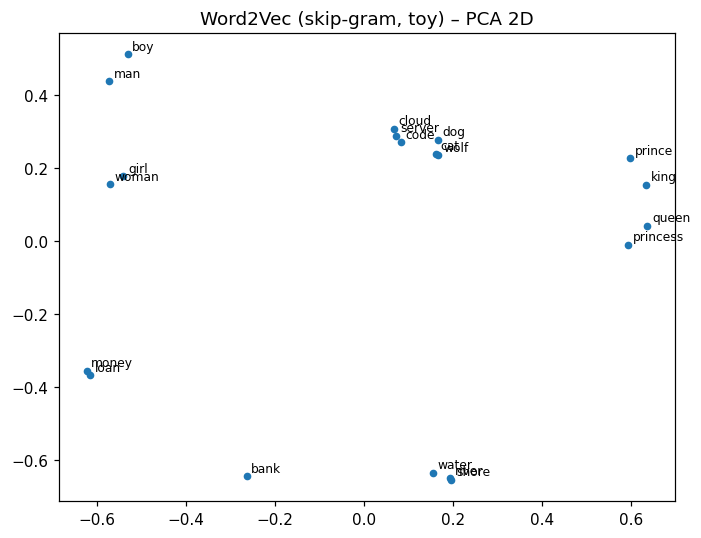

In [22]:
# Trực quan hoá không gian vector bằng PCA 2D (SVD)
words = ["king", "queen", "prince", "princess", "man", "woman", "boy", "girl",
         "money", "loan", "bank", "river", "water", "shore", "dog", "cat", "wolf", "server", "code", "cloud"]
P = np.array([M[i[w]] for w in words]); P = P - P.mean(0)
U, S_, Vt = np.linalg.svd(P, full_matrices=False)
xy = P @ Vt[:2].T
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(xy[:, 0], xy[:, 1], s=16)
for w, (x, y) in zip(words, xy):
    ax.annotate(w, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax.set_title("Word2Vec (skip-gram, toy) – PCA 2D"); plt.tight_layout(); plt.show()

### 6.2 GloVe-style: PPMI + SVD
GloVe kết hợp **ngữ cảnh cục bộ** (như Word2Vec) với **thống kê đồng xuất hiện toàn cục** (phân rã ma trận). Phiên bản đơn giản tương đương: dựng ma trận đồng xuất hiện toàn corpus → PPMI → SVD. (Đây là họ phương pháp *count-based*, được chứng minh có quan hệ chặt với skip-gram.)

In [23]:
def ppmi_svd(sentences, window=3, dim=30):
    vocab = sorted({w for s in sentences for w in s}); ix = {w: k for k, w in enumerate(vocab)}
    C = np.zeros((len(vocab), len(vocab)))
    for s in sentences:
        for a in range(len(s)):
            for b in range(max(0, a - window), min(len(s), a + window + 1)):
                if a != b: C[ix[s[a]], ix[s[b]]] += 1
    total = C.sum(); pw = C.sum(1, keepdims=True) / total; pc = C.sum(0, keepdims=True) / total
    with np.errstate(divide="ignore"):
        pmi = np.log((C / total) / (pw @ pc))
    ppmi = np.maximum(pmi, 0); ppmi[~np.isfinite(ppmi)] = 0
    U, S_, _ = np.linalg.svd(ppmi, full_matrices=False)
    E = U[:, :dim] * np.sqrt(S_[:dim])
    return vocab, ix, E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)

pv, pix, E = ppmi_svd(sentences)
def nn(word, n=5):
    s = E @ E[pix[word]]
    return [(str(pv[k]), round(float(s[k]), 3)) for k in np.argsort(-s) if pv[k] != word][:n]

for w in ["bank", "dog", "queen", "server"]:
    print(f"{w:8s} ->", nn(w))

q = E[pix["king"]] - E[pix["man"]] + E[pix["woman"]]
s = E @ (q / np.linalg.norm(q))
print("\nking - man + woman ->", [(str(pv[k]), round(float(s[k]), 3)) for k in np.argsort(-s) if pv[k] not in {"king", "man", "woman"}][:3])

bank     -> [('stream', 0.706), ('mud', 0.69), ('water', 0.663), ('fish', 0.653), ('boat', 0.642)]
dog      -> [('hunts', 1.0), ('cat', 1.0), ('barks', 0.997), ('fox', 0.996), ('bird', 0.996)]
queen    -> [('king', 0.776), ('princess', 0.519), ('palace', 0.489), ('crown', 0.471), ('castle', 0.424)]
server   -> [('cloud', 0.999), ('model', 0.995), ('program', 0.993), ('software', 0.993), ('computer', 0.983)]

king - man + woman -> [('queen', 0.851), ('princess', 0.611), ('palace', 0.381)]


### 6.3 FastText – subword embeddings
Mỗi từ = tổng các **character n-gram** (`<ki`, `kin`, `ing`, `ngd`, ...). Nhờ vậy tạo được vector cho **từ chưa từng xuất hiện (OOV)** và hữu ích với ngôn ngữ giàu hình thái. Bài báo nêu FastText cải thiện rõ trên tác vụ syntactic analogy.

In [24]:
print("Các n-gram của 'kingdoms':", char_ngrams("kingdoms")[:10], "...")

# Huấn luyện FastText (toy) trên corpus nhưng LOẠI các câu chứa 'kingdoms' để biến nó thành OOV
train_ft = [s for s in sentences if "kingdoms" not in s]
ft = SkipGram(train_ft, dim=32, window=3, neg=5, lr=0.05, subword=True, seed=0).fit(epochs=3)
w2v_oov = SkipGram(train_ft, dim=32, window=3, neg=5, lr=0.05, subword=False, seed=0).fit(epochs=3)

print("'kingdoms' trong từ điển?", "kingdoms" in ft.w2i)
v = ft.vec("kingdoms")
M_ft = ft.matrix(); sims = M_ft @ (v / np.linalg.norm(v))
print("FastText – từ gần 'kingdoms' (OOV):", [(str(ft.vocab[k]), round(float(sims[k]), 3)) for k in np.argsort(-sims)[:5]])
print("Word2Vec – vector cho 'kingdoms':", w2v_oov.vec("kingdoms"), "(không có, vì OOV)")

Các n-gram của 'kingdoms': ['<ki', 'kin', 'ing', 'ngd', 'gdo', 'dom', 'oms', 'ms>', '<kin', 'king'] ...
'kingdoms' trong từ điển? False
FastText – từ gần 'kingdoms' (OOV): [('kingdom', 1.0), ('rules', 1.0), ('throne', 0.999), ('palace', 0.999), ('royal', 0.999)]
Word2Vec – vector cho 'kingdoms': None (không có, vì OOV)


### 6.4 Dynamic (contextual) embeddings
Embedding tĩnh cho **mỗi từ một vector** nên không phân biệt *bank* (ngân hàng) với *bank* (bờ sông). CoVe, ELMo, GPT, BERT... tính vector **phụ thuộc cả câu**. Dưới đây mô phỏng cơ chế cốt lõi bằng một lớp **self-attention** đơn giản: vector ngữ cảnh của từ = vector tĩnh + trung bình có trọng số (softmax của độ tương đồng) của các từ trong câu.

In [25]:
def contextual(sentence, target, E, ix, temp=0.3):
    words = sentence.split()
    Vs = np.array([E[ix[w]] for w in words if w in ix])
    ws = [w for w in words if w in ix]
    q = E[ix[target]]
    att = np.exp(Vs @ q / temp); att /= att.sum()            # attention weights
    ctx = (att[:, None] * Vs).sum(0)
    out = q + ctx
    return out / np.linalg.norm(out), dict(zip(ws, att.round(2).tolist()))

s1 = "bank loan deposit money account"
s2 = "bank river water shore boat"
v1, a1 = contextual(s1, "bank", E, pix)
v2, a2 = contextual(s2, "bank", E, pix)

static = E[pix["bank"]]
rows = []
for name, vec in [("static", static), ("context: finance", v1), ("context: river", v2)]:
    rows.append([name, float(vec @ E[pix["money"]]), float(vec @ E[pix["river"]])])
display(pd.DataFrame(rows, columns=["bank (loại vector)", "cos với 'money'", "cos với 'river'"]).round(3))
print("Attention (finance):", a1); print("Attention (river)  :", a2)
print("\ncos(bank|finance, bank|river) =", round(float(v1 @ v2), 3), "  (<1: hai nghĩa tách ra)")

,bank (loại vector),cos với 'money',cos với 'river'
0,static,0.598,0.638
1,context: finance,0.754,0.527
2,context: river,0.470,0.789


Attention (finance): {'bank': 0.51, 'loan': 0.1, 'deposit': 0.14, 'money': 0.13, 'account': 0.11}
Attention (river)  : {'bank': 0.45, 'river': 0.14, 'water': 0.15, 'shore': 0.13, 'boat': 0.14}

cos(bank|finance, bank|river) = 0.924   (<1: hai nghĩa tách ra)


**Dùng BERT thật** (cần `transformers` + `torch` và có Internet – không chạy được trong môi trường demo này nên để ở dạng comment). Cùng từ *bank* sẽ cho hai vector khác nhau tuỳ ngữ cảnh – đúng như BERT *bidirectional* với Masked LM trong bài báo:

```python
# pip install transformers torch
import torch
from transformers import AutoTokenizer, AutoModel
tok = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased").eval()

def word_vec(sentence, word):
    enc = tok(sentence, return_tensors="pt")
    with torch.no_grad():
        h = model(**enc).last_hidden_state[0]
    pos = tok.convert_ids_to_tokens(enc["input_ids"][0]).index(word)
    return h[pos]

v_fin = word_vec("I deposited cash at the bank.", "bank")
v_riv = word_vec("We sat on the river bank.", "bank")
print(torch.cosine_similarity(v_fin, v_riv, dim=0))   # < 1: embedding phụ thuộc ngữ cảnh
```

Với dữ liệu đa ngôn ngữ/đa phương thức, bài báo còn khảo sát M-BERT, XLM, XLM-R (cross-lingual); ERNIE, K-BERT, KEPLER (knowledge-enriched); BioBERT, SciBERT (domain-specific); VisualBERT, ViLBERT, VideoBERT (multi-modal); CamemBERT, FinBERT, BERTje, AraBERT (language-specific).

## 7. Tổng kết

Bảng dưới đây gom lại tiến trình tiến hoá của các kỹ thuật, theo đúng tinh thần của bài survey: **từ chỗ chỉ hiểu từng "mảnh" văn bản → hiểu được ngữ nghĩa và ngữ cảnh.**

In [26]:
summary = pd.DataFrame([
 ["Regex / Fuzzy CFG", "Rule-based",        "Khớp mẫu, trả lời theo kịch bản",          "Cứng nhắc, không có ngữ nghĩa"],
 ["One-Hot",           "Discrete",          "Giữ nguyên thứ tự từ, tái tạo được câu",  "Thưa, nhiều chiều, dot = 0"],
 ["Bag of Words",      "Discrete",          "Gọn hơn OHE, so sánh tài liệu",            "Mất thứ tự, không nhận đồng nghĩa"],
 ["Category-based",    "Discrete",          "Rất ít chiều (theo nhãn/lexicon)",         "Mất cú pháp và thứ tự"],
 ["N-gram",            "Discrete",          "Giữ thứ tự cục bộ ('not like')",           "Bùng nổ tổ hợp, thưa"],
 ["TF / NTF",          "Discrete",          "Chuẩn hoá theo độ dài tài liệu",           "Coi từ độc lập, từ phổ biến lấn át"],
 ["TF-IDF",            "Discrete",          "Nhấn mạnh từ đặc trưng cho tài liệu",      "Nhiều chiều, không nối được đồng nghĩa"],
 ["HAL",               "Discrete (co-occ.)","Nghĩa suy ra từ ngữ cảnh gần",             "Từ tần suất cao chi phối độ tương tự"],
 ["DF/TFV/TI/IG",      "DR – selection",    "Giữ top-k đặc trưng",                      "Bỏ phần còn lại"],
 ["LSI (SVD)",         "DR – transform",    "Gom từ đồng xuất hiện thành chủ đề",       "Không giải quyết đa nghĩa"],
 ["PLSI / LDA",        "DR – transform",    "Chủ đề xác suất, xử lý đa nghĩa (LDA tổng quát hoá)", "Huấn luyện chậm (LDA)"],
 ["ICA",               "DR – transform",    "Thành phần độc lập thống kê",              "Giả định phi-Gaussian"],
 ["Random Indexing",   "DR – transform",    "Incremental, nhanh, giữ khoảng cách (J-L)", "Chiều mới ngẫu nhiên, không thứ tự"],
 ["ESA",               "Conceptual",        "Khái niệm kiểu Wikipedia, giải thích được", "Phụ thuộc kho tri thức ngoài"],
 ["Gaussian emb.",     "Density",           "Biểu diễn độ bất định, entailment",        "Đơn mode không biểu diễn đa nghĩa"],
 ["Word2Vec/GloVe",    "Neural – static",   "Vector dày 100–500 chiều, analogy",        "1 vector/từ, không theo ngữ cảnh"],
 ["FastText",          "Neural – static",   "Subword, xử lý OOV, ngôn ngữ giàu hình thái", "Vẫn tĩnh"],
 ["ELMo/GPT/BERT...",  "Neural – dynamic",  "Vector phụ thuộc ngữ cảnh, giải quyết đa nghĩa", "Cần dữ liệu & tính toán lớn, thiên kiến"],
 ["Fine-tuned (XLM-R, BioBERT, ERNIE, VisualBERT...)", "Neural – fine-tuning", "Cross-lingual, domain, knowledge, multimodal", "Thiên kiến, khó diễn giải, quyền riêng tư"],
], columns=["Kỹ thuật", "Nhóm", "Giải quyết được", "Hạn chế"])
display(summary)

,Kỹ thuật,Nhóm,Giải quyết được,Hạn chế
0,Regex / Fuzzy CFG,Rule-based,"Khớp mẫu, trả lời theo kịch bản","Cứng nhắc, không có ngữ nghĩa"
1,One-Hot,Discrete,"Giữ nguyên thứ tự từ, tái tạo được câu","Thưa, nhiều chiều, dot = 0"
2,Bag of Words,Discrete,"Gọn hơn OHE, so sánh tài liệu","Mất thứ tự, không nhận đồng nghĩa"
3,Category-based,Discrete,Rất ít chiều (theo nhãn/lexicon),Mất cú pháp và thứ tự
4,N-gram,Discrete,Giữ thứ tự cục bộ ('not like'),"Bùng nổ tổ hợp, thưa"
5,TF / NTF,Discrete,Chuẩn hoá theo độ dài tài liệu,"Coi từ độc lập, từ phổ biến lấn át"
6,TF-IDF,Discrete,Nhấn mạnh từ đặc trưng cho tài liệu,"Nhiều chiều, không nối được đồng nghĩa"
7,HAL,Discrete (co-occ.),Nghĩa suy ra từ ngữ cảnh gần,Từ tần suất cao chi phối độ tương tự
8,DF/TFV/TI/IG,DR – selection,Giữ top-k đặc trưng,Bỏ phần còn lại
9,LSI (SVD),DR – transform,Gom từ đồng xuất hiện thành chủ đề,Không giải quyết đa nghĩa


### Tài liệu tham khảo
R. Patil, S. Boit, V. Gudivada, J. Nandigam, *"A Survey of Text Representation and Embedding Techniques in NLP"*, **IEEE Access**, vol. 11, pp. 36120–36146, 2023. DOI: 10.1109/ACCESS.2023.3266377.